# Low-data fine-tuning: linear probe vs partial FT vs full FT vs LoRA

ML4CV project work (Prof. S. Salti).

**Question.** How does the best adaptation strategy of a pre-trained backbone change with the amount of labelled data?

**Hypotheses (written before running any experiment).**
1. With 1-5 examples per class, linear probe and LoRA are at least as good as full fine-tuning (which overfits).
2. With more data full fine-tuning catches up and eventually wins: there is a crossover point.
3. CLIP features are better than supervised ImageNet features in the low-shot regime.

**Protocol.** Fixed hyperparameters per method (no tuning on the test set), 3 seeds (0, 1, 2) for every configuration, mean and std reported.

### Notebook map

| section | what it does |
|---|---|
| Main study | Flowers102 and Pets, 2 backbones, 4 methods, 1 / 5 / all images per class, fixed hyperparameters (exploratory) |
| Ablations | LoRA rank, unfrozen blocks, linear-probe budget (Flowers102, CLIP) |
| Replication | CLIP-LoRA protocol re-implemented, as a check of the pipeline |
| Discussion, published results | verdicts on H1-H3 and comparison with the literature |
| Scaling study (EuroSAT) | tuned learning rates, 1 to 1,500 images/class, both backbones; **the verdicts rest on it** |
| Budget check | longer training for full FT and LoRA |

Figures and tables are printed in the analysis cells. Run cells can be interrupted and resumed (finished runs are skipped).


In [1]:
# Configuration cell: imports, experiment grid and every hyperparameter of the main study.
import itertools, math, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import ConcatDataset, DataLoader, Subset
import torchvision
from torchvision import transforms as T

# Experiment grid of the main study: 3 seeds x 2 datasets x 2 backbones x 4 methods x 3 shot settings.
SEEDS = [0, 1, 2]
DATASETS = ['flowers102', 'pets']
BACKBONES = ['clip_vitb16', 'vit_b16_sup']
METHODS = ['linear_probe', 'partial_ft', 'full_ft', 'lora']
SHOTS = [1, 5, 'full']          # images per class; 'full' = the whole training pool (20/class Flowers, about 100/class Pets)
PARTIAL_K = 4                   # number of last transformer blocks unfrozen by partial_ft
LORA_RANK = 8
DATA_ROOT = Path('data')
RESULTS_CSV = Path('results/results.csv')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# Hyperparameters: fixed a priori from common defaults, identical for every dataset/backbone/shot, never tuned on the test set.
TIMM_NAME = {
    'clip_vitb16': 'vit_base_patch16_clip_224.openai',      # OpenAI CLIP image tower (no projection / text tower)
    'vit_b16_sup': 'vit_base_patch16_224.augreg_in1k',      # supervised, ImageNet-1k only
}
BATCH_SIZE = 32
EPOCHS = 10          # passes over the training subset ...
MIN_STEPS = 100      # ... but never fewer optimizer steps than this (1-shot subsets are tiny)
MAX_STEPS = 10**9    # cap on optimizer steps (not binding in the main study; used for the large-data scaling study)
WEIGHT_DECAY = 0.01
HEAD_LR = 1e-3                  # learning rate of the new linear head (all methods)
BODY_LR = {'partial_ft': 1e-5, 'full_ft': 1e-5, 'lora': 5e-4}  # learning rate of the backbone parameters that are trained
LORA_ALPHA = 16                 # LoRA scale = LORA_ALPHA / LORA_RANK
WARMUP_FRAC = 0.1               # fraction of the steps used for linear learning-rate warm-up
NUM_WORKERS = 8

def set_seed(seed):
    # Seeds every RNG used by a run (subset sampling, head/LoRA init, augmentation, shuffling) for reproducibility.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


## Data

Flowers102 uses train+val as training pool (20 images/class) and the official test split. Pets uses `trainval` and `test`. K-shot subsets are sampled per seed from the training pool.

In [2]:
# Data cell: preprocessing, dataset loading, k-shot sampling and a cached uint8 test set.

# Per-backbone input normalisation (mean, std); each backbone must see the statistics it was pre-trained with.
NORM = {
    'clip_vitb16': ((0.4815, 0.4578, 0.4082), (0.2686, 0.2613, 0.2758)),
    'vit_b16_sup': ((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
}

def get_transform(backbone, train):
    mean, std = NORM[backbone]
    if train:
        # light augmentation at training time: random crop (keeps at least half of the image) + horizontal flip
        aug = [T.RandomResizedCrop(224, scale=(0.5, 1.0)), T.RandomHorizontalFlip()]
    else:
        # deterministic evaluation: resize to 256 and centre-crop 224
        aug = [T.Resize(256), T.CenterCrop(224)]
    return T.Compose(aug + [T.ToTensor(), T.Normalize(mean, std)])

def load_dataset(name, backbone, test_tf=None, train_tf=None):
    """Return (training dataset, training labels, test dataset); transforms must be passed to the constructors."""
    tf_train, tf_test = train_tf or get_transform(backbone, True), test_tf or get_transform(backbone, False)
    root = DATA_ROOT / name
    if name == 'flowers102':
        mk = lambda split, tf: torchvision.datasets.Flowers102(root, split=split, transform=tf, download=True)
        # train + val together give the training pool (20 images per class); the official test split is the test set
        train = ConcatDataset([mk('train', tf_train), mk('val', tf_train)])
        labels = list(mk('train', None)._labels) + list(mk('val', None)._labels)  # _labels is private in torchvision
        test = mk('test', tf_test)
    elif name == 'pets':
        train = torchvision.datasets.OxfordIIITPet(root, split='trainval', transform=tf_train, download=True)
        labels = list(train._labels)
        test = torchvision.datasets.OxfordIIITPet(root, split='test', transform=tf_test, download=True)
    else:
        raise ValueError(name)
    return train, labels, test

def few_shot_indices(labels, shots, seed):
    # Sample `shots` images per class without replacement; the same seed gives the same subset for every method and backbone.
    if shots == 'full':
        return list(range(len(labels)))
    rng = np.random.default_rng(seed)
    labels = np.asarray(labels)
    idx = [rng.choice(np.flatnonzero(labels == c), shots, replace=False) for c in np.unique(labels)]
    return np.concatenate(idx).tolist()

_TEST_CACHE = {}

def cached_test_set(name):
    """Test preprocessing is deterministic: decode once as uint8; normalisation is applied on the GPU per backbone."""
    if name not in _TEST_CACHE:
        test = load_dataset(name, 'vit_b16_sup', T.Compose([T.Resize(256), T.CenterCrop(224), T.PILToTensor()]))[2]
        xs, ys = zip(*DataLoader(test, batch_size=128, num_workers=NUM_WORKERS))
        assert xs[0].dtype == torch.uint8
        _TEST_CACHE[name] = (torch.cat(xs), torch.cat(ys))
    return _TEST_CACHE[name]


## Models and methods

| method | trainable parameters |
|---|---|
| `linear_probe` | linear head on frozen features |
| `partial_ft` | head + last `PARTIAL_K` transformer blocks + final norm |
| `full_ft` | everything |
| `lora` | head + LoRA adapters (rank `LORA_RANK`, scale `LORA_ALPHA / LORA_RANK`) on `qkv` and `proj` of every block |

Backbones come from `timm`: `vit_base_patch16_clip_224.openai` (CLIP image tower only, no projection, no text tower) and `vit_base_patch16_224.augreg_in1k` (supervised, ImageNet-1k only). The head is a new linear layer initialised at zero.

**Training protocol (identical for all datasets, backbones and shot counts).** AdamW, weight decay 0.01, batch 32 (smaller if the subset is smaller), bf16 autocast, linear warm-up (10%) + cosine decay, no early stopping and no validation set. Budget: 10 epochs over the training subset, at least 100 steps. Learning rates: head 1e-3; backbone 1e-5 for `partial_ft` / `full_ft`, 5e-4 for LoRA parameters. The values are common defaults chosen before any run; they are not tuned, so a method may be under- or over-tuned for a given regime (see limitations). The k-shot subset of a given seed is the same for every method and backbone (paired comparison).


In [3]:
# Models cell: LoRA layer, model construction per method, optimiser, evaluation, training loop and one full run.

class LoRALinear(nn.Module):
    """Frozen linear layer W plus a trainable low-rank update: y = W x + (alpha / rank) * B A x."""
    def __init__(self, base, rank, alpha):
        super().__init__()
        self.base = base
        self.A = nn.Parameter(torch.empty(rank, base.in_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, rank))  # zero init: starts equal to the pre-trained model
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.scale = alpha / rank

    def forward(self, x):
        return self.base(x) + (x @ self.A.T @ self.B.T) * self.scale

def build_model(backbone, method, num_classes):
    # Pre-trained ViT with a new linear head initialised at zero (so every run starts from uniform logits).
    model = timm.create_model(TIMM_NAME[backbone], pretrained=True, num_classes=num_classes)
    nn.init.zeros_(model.head.weight)
    nn.init.zeros_(model.head.bias)
    # Freeze everything, except for full fine-tuning where all parameters stay trainable.
    for p in model.parameters():
        p.requires_grad = method == 'full_ft'
    if method == 'partial_ft':
        # unfreeze the last PARTIAL_K transformer blocks and the final layer norm
        for mod in [*model.blocks[-PARTIAL_K:], model.norm]:
            for p in mod.parameters():
                p.requires_grad = True
    elif method == 'lora':
        # wrap the attention input (qkv) and output (proj) projections of every block with a LoRA update
        for blk in model.blocks:
            blk.attn.qkv = LoRALinear(blk.attn.qkv, LORA_RANK, LORA_ALPHA)
            blk.attn.proj = LoRALinear(blk.attn.proj, LORA_RANK, LORA_ALPHA)
    # the head is trained by every method (including the linear probe)
    for p in model.head.parameters():
        p.requires_grad = True
    return model

def make_optimizer(model, method):
    # Two parameter groups: the new head (HEAD_LR) and the trained backbone parameters (BODY_LR[method]), if any.
    head = list(model.head.parameters())
    head_ids = {id(p) for p in head}
    body = [p for p in model.parameters() if p.requires_grad and id(p) not in head_ids]
    groups = [dict(params=head, lr=HEAD_LR)]
    if body:
        groups.append(dict(params=body, lr=BODY_LR[method]))
    return torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)

@torch.no_grad()
def evaluate(model, backbone, x_u8, y, bs=128):
    """Top-1 accuracy on uint8 images already on the CPU; normalisation is done here on the GPU."""
    model.eval()
    mean, std = (torch.tensor(v, device=DEVICE).view(1, 3, 1, 1) for v in NORM[backbone])
    correct = 0
    for i in range(0, len(y), bs):
        x = (x_u8[i:i + bs].to(DEVICE).float() / 255 - mean) / std
        with torch.autocast(DEVICE, dtype=torch.bfloat16):
            correct += (model(x).argmax(1).cpu() == y[i:i + bs]).sum().item()
    return correct / len(y)

def train(model, loader, method):
    # Budget: EPOCHS passes over the subset, clipped to [MIN_STEPS, MAX_STEPS] optimizer steps.
    steps = min(MAX_STEPS, max(MIN_STEPS, EPOCHS * len(loader)))
    warmup = max(1, int(WARMUP_FRAC * steps))
    opt = make_optimizer(model, method)
    # linear warm-up, then cosine decay to zero
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warmup if s < warmup else 0.5 * (1 + math.cos(math.pi * (s - warmup) / (steps - warmup))))
    model.train()
    step = 0
    while step < steps:  # the loader is cycled until the step budget is used up
        for x, y in loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with torch.autocast(DEVICE, dtype=torch.bfloat16):
                loss = F.cross_entropy(model(x).float(), y)  # loss in float32 for numerical stability
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
            step += 1
            if step == steps:
                break
    return loss.item()

def run_one(dataset, backbone, method, shots, seed):
    # One configuration: seed, sample the k-shot subset, build the model, train, return the test accuracy.
    # No validation set and no early stopping: the model after the last step is evaluated.
    set_seed(seed)
    train_ds, labels, _ = load_dataset(dataset, backbone)
    idx = few_shot_indices(labels, shots, seed)
    model = build_model(backbone, method, len(set(labels))).to(DEVICE)
    loader = DataLoader(Subset(train_ds, idx), batch_size=min(BATCH_SIZE, len(idx)), shuffle=True,
                        num_workers=NUM_WORKERS, pin_memory=True)
    train(model, loader, method)
    return evaluate(model, backbone, *cached_test_set(dataset))


## Experiments

The loop skips configurations already done, so it can be interrupted and resumed.


In [4]:
# Main experiment loop: 144 runs, each appended to the CSV as soon as it finishes, so the cell can be interrupted and resumed.
RESULTS_CSV.parent.mkdir(exist_ok=True)

def done_keys():
    # Configurations already in the CSV; shots are compared as strings because 'full' is not a number.
    if not RESULTS_CSV.exists():
        return set()
    df = pd.read_csv(RESULTS_CSV)
    return set(zip(df.dataset, df.backbone, df.method, df.shots.astype(str), df.seed))

done = done_keys()
for ds, bb, m, k, s in itertools.product(DATASETS, BACKBONES, METHODS, SHOTS, SEEDS):
    if (ds, bb, m, str(k), s) in done:
        continue
    t0 = time.time()
    test_acc = run_one(ds, bb, m, k, s)
    row = dict(dataset=ds, backbone=bb, method=m, shots=k, seed=s, test_acc=test_acc, time_s=time.time() - t0)
    pd.DataFrame([row]).to_csv(RESULTS_CSV, mode='a', header=not RESULTS_CSV.exists(), index=False)


## Results

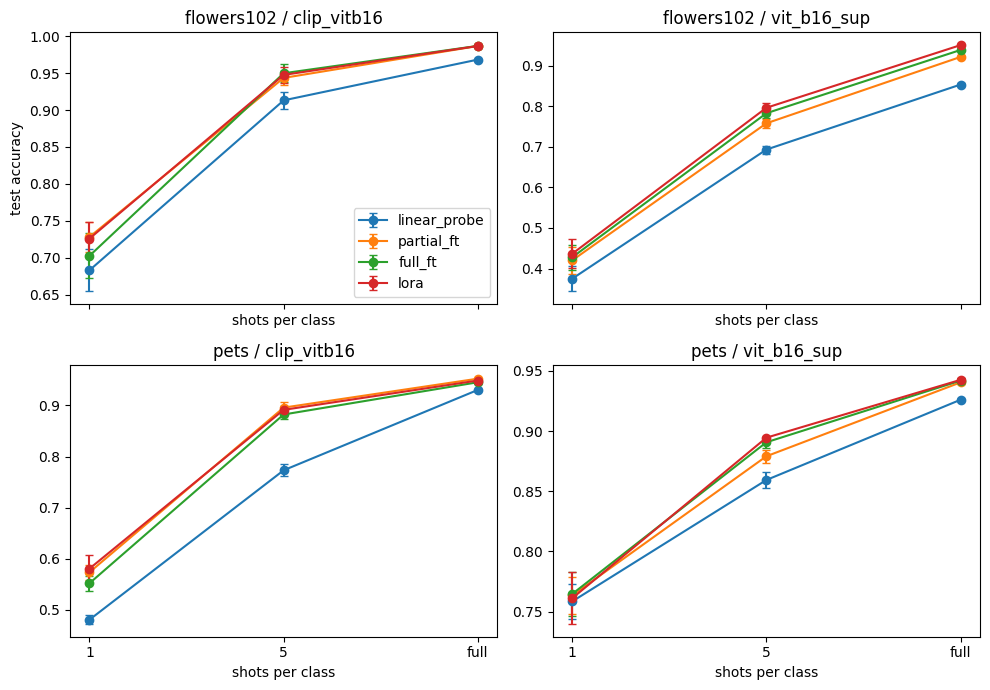

mean     std
dataset    backbone    method       shots                
flowers102 clip_vitb16 full_ft      1      0.7028  0.0305
                                    5      0.9497  0.0123
                                    full   0.9867  0.0009
                       linear_probe 1      0.6833  0.0284
                                    5      0.9130  0.0117
                                    full   0.9682  0.0012
                       lora         1      0.7261  0.0222
                                    5      0.9475  0.0105
                                    full   0.9866  0.0018
                       partial_ft   1      0.7282  0.0199
                                    5      0.9434  0.0099
                                    full   0.9866  0.0007
           vit_b16_sup full_ft      1      0.4277  0.0312
                                    5      0.7828  0.0123
                                    full   0.9386  0.0006
                       linear_probe 1      0.3749  0.0310
                                    5      0.6932  0.0100
                                    full   0.8535  0.0027
                       lora         1      0.4364  0.0356
                                    5      0.7962  0.0126
                                    full   0.9506  0.0011
                       partial_ft   1      0.4202  0.0337
                                    5      0.7580  0.0114
                                    full   0.9215  0.0014
pets       clip_vitb16 full_ft      1      0.5519  0.0150
                                    5      0.8823  0.0087
                                    full   0.9455  0.0035
                       linear_probe 1      0.4806  0.0091
                                    5      0.7731  0.0120
                                    full   0.9305  0.0012
                       lora         1      0.5805  0.0275
                                    5      0.8914  0.0083
                                    full   0.9489  0.0019
                       partial_ft   1      0.5735  0.0146
                                    5      0.8958  0.0111
                                    full   0.9525  0.0018
           vit_b16_sup full_ft      1      0.7646  0.0185
                                    5      0.8907  0.0046
                                    full   0.9419  0.0017
                       linear_probe 1      0.7584  0.0144
                                    5      0.8594  0.0070
                                    full   0.9260  0.0006
                       lora         1      0.7611  0.0217
                                    5      0.8945  0.0007
                                    full   0.9426  0.0018
                       partial_ft   1      0.7634  0.0153
                                    5      0.8791  0.0055
                                    full   0.9405  0.0015

In [5]:
# Results cell: accuracy versus shots for every dataset/backbone/method (mean +- std over the 3 seeds) and the summary table.
import matplotlib.pyplot as plt

df = pd.read_csv(RESULTS_CSV).assign(shots=lambda d: d.shots.astype(str))
shot_labels = [str(k) for k in SHOTS]
summary = df.groupby(['dataset', 'backbone', 'method', 'shots']).test_acc.agg(['mean', 'std']).round(4)

# one panel per (dataset, backbone); x axis = shot setting (categorical because 'full' differs per dataset), one line per method
fig, axes = plt.subplots(len(DATASETS), len(BACKBONES), figsize=(10, 7), sharex=True, squeeze=False)
for i, ds in enumerate(DATASETS):
    for j, bb in enumerate(BACKBONES):
        ax = axes[i, j]
        for m in METHODS:
            g = df[(df.dataset == ds) & (df.backbone == bb) & (df.method == m)].groupby('shots').test_acc.agg(['mean', 'std']).reindex(shot_labels)
            ax.errorbar(range(len(g)), g['mean'], g['std'], marker='o', capsize=3, label=m)
        ax.set(xticks=range(len(shot_labels)), xticklabels=shot_labels, title=f'{ds} / {bb}')
        ax.set_xlabel('shots per class')
axes[0, 0].set_ylabel('test accuracy')
axes[0, 0].legend()
plt.tight_layout()
plt.show()
summary


As we can see, in the ViT B-16 with supervised setting, LoRA is the best among all the other strategies for each number of shots on Flowers102, and on Pets with 5 shots and with all the data. The only exception is Pets with 1 shot, where full fine-tuning is marginally ahead (0.765 vs 0.761, within seed noise). In the CLIP setting, instead, there is no single winner: LoRA is the best or within 0.005 of the best in every cell, but it is the top method only on Pets with 1 shot, while partial fine-tuning has the highest mean on Flowers with 1 shot and on Pets with 5 shots and with all the data, and full fine-tuning on Flowers with 5 shots (with all the data on Flowers the three methods tie at 0.987). With 1 shot full fine-tuning is the weakest of the three adapted methods (0.703 vs 0.726-0.728 on Flowers, 0.552 vs 0.573-0.581 on Pets), consistent with a mild overfitting effect, and the gap closes as the number of shots grows. In both settings the linear probe is the weakest strategy in almost every cell (the only tie is Pets with the supervised backbone and 1 shot), and the gap is larger for the supervised backbone on Flowers (about 0.06-0.10 below LoRA). Differences below about 0.01 are within the seed-to-seed standard deviation and should be read as ties; these runs use fixed, untuned learning rates, so they are exploratory (see the scaling study with tuned learning rates for the conclusions).


### Paired differences

The same seed gives the same k-shot subset to every method and backbone, so subtracting accuracies seed by seed removes the variance due to the subset. The first table gives full FT minus the linear probe and minus LoRA (> 0: full FT better); the second gives CLIP minus supervised (> 0: CLIP better, H3). Differences smaller than about 0.01, or smaller than the std, should be read as ties.


In [6]:
# Paired differences (same seed => same k-shot subset). H1/H2: full_ft vs the cheaper methods; H3: CLIP vs supervised.
# Pairing removes the variance due to the choice of the subset, so small differences are easier to see than with the plain means.
# String order '1' < '5' < 'full' matches the shot order.
acc = df.pivot_table(index=['dataset', 'backbone', 'shots', 'seed'], columns='method', values='test_acc')
paired = pd.DataFrame({'full_ft - linear_probe': acc.full_ft - acc.linear_probe, 'full_ft - lora': acc.full_ft - acc.lora})
display(paired.groupby(['dataset', 'backbone', 'shots']).agg(['mean', 'std']).round(3))

# H3: same dataset, method, shots and seed, CLIP minus supervised (> 0 means CLIP is better)
by_bb = df.pivot_table(index=['dataset', 'method', 'shots', 'seed'], columns='backbone', values='test_acc')
clip_gain = (by_bb.clip_vitb16 - by_bb.vit_b16_sup).rename('clip - sup')
clip_gain.groupby(['dataset', 'method', 'shots']).agg(['mean', 'std']).round(3)


full_ft - linear_probe        full_ft - lora  \
                                               mean    std           mean   
dataset    backbone    shots                                                
flowers102 clip_vitb16 1                      0.020  0.014         -0.023   
                       5                      0.037  0.001          0.002   
                       full                   0.019  0.002          0.000   
           vit_b16_sup 1                      0.053  0.008         -0.009   
                       5                      0.090  0.009         -0.013   
                       full                   0.085  0.003         -0.012   
pets       clip_vitb16 1                      0.071  0.011         -0.029   
                       5                      0.109  0.017         -0.009   
                       full                   0.015  0.004         -0.003   
           vit_b16_sup 1                      0.006  0.004          0.004   
                       5                      0.031  0.003         -0.004   
                       full                   0.016  0.002         -0.001   

                                     
                                std  
dataset    backbone    shots         
flowers102 clip_vitb16 1      0.020  
                       5      0.003  
                       full   0.002  
           vit_b16_sup 1      0.006  
                       5      0.005  
                       full   0.001  
pets       clip_vitb16 1      0.013  
                       5      0.001  
                       full   0.005  
           vit_b16_sup 1      0.006  
                       5      0.005  
                       full   0.003

mean    std
dataset    method       shots              
flowers102 full_ft      1      0.275  0.011
                        5      0.167  0.007
                        full   0.048  0.001
           linear_probe 1      0.308  0.005
                        5      0.220  0.003
                        full   0.115  0.003
           lora         1      0.290  0.018
                        5      0.151  0.002
                        full   0.036  0.002
           partial_ft   1      0.308  0.015
                        5      0.185  0.002
                        full   0.065  0.001
pets       full_ft      1     -0.213  0.026
                        5     -0.008  0.010
                        full   0.004  0.005
           linear_probe 1     -0.278  0.023
                        5     -0.086  0.018
                        full   0.004  0.002
           lora         1     -0.181  0.042
                        5     -0.003  0.008
                        full   0.006  0.004
           partial_ft   1     -0.190  0.018
                        5      0.017  0.016
                        full   0.012  0.003

## Ablations

Scope: Flowers102, CLIP ViT-B/16, 1 and 5 shots, 3 seeds (same k-shot subsets as the main study). One factor is changed at a time; the reference value is the main-study run (LoRA rank 8, `PARTIAL_K` 4, linear probe 100+ steps with head lr 1e-3).

1. **LoRA rank** in {1, 2, 4, 8, 16}.
2. **Number of unfrozen blocks** `PARTIAL_K` in {1, 2, 4, 8, 12}; 12 = all transformer blocks, which differs from `full_ft` only in the patch embedding and positional embeddings.
3. **Linear-probe budget** (sensitivity check for H1): 500 steps, or head lr 1e-2 instead of 1e-3.

These runs are a sensitivity analysis on the test set: they do not replace the fixed hyperparameters of the main study, and no value is selected from them.


In [7]:
# Ablation runs: one factor changed at a time on Flowers102 / CLIP / 1 and 5 shots; resumable, one CSV row per run.
ABLATION_CSV = Path('results/ablation.csv')
ABL_DATASET, ABL_BACKBONE, ABL_SHOTS = 'flowers102', 'clip_vitb16', [1, 5]
# (study, method, global to override, values to run); the main-study value of each factor is not re-run (taken from the main results)
ABLATIONS = [
    ('lora_rank', 'lora', 'LORA_RANK', [1, 2, 4, 16]),
    ('partial_k', 'partial_ft', 'PARTIAL_K', [1, 2, 8, 12]),
    ('lp_min_steps', 'linear_probe', 'MIN_STEPS', [500]),
    ('lp_head_lr', 'linear_probe', 'HEAD_LR', [1e-2]),
]

def run_ablation(method, var, value, shots, seed):
    # Temporarily override a module-level hyperparameter, run, and always restore the default.
    default = globals()[var]
    globals()[var] = value
    try:
        return run_one(ABL_DATASET, ABL_BACKBONE, method, shots, seed)
    finally:
        globals()[var] = default

def abl_done():
    if not ABLATION_CSV.exists():
        return set()
    d = pd.read_csv(ABLATION_CSV)
    return set(zip(d.study, d.value.astype(float), d.shots, d.seed))

done_abl = abl_done()
for (study, method, var, values), value, k, s in ((a, v, k, s) for a in ABLATIONS for v in a[3] for k in ABL_SHOTS for s in SEEDS):
    if (study, float(value), k, s) in done_abl:
        continue
    t0 = time.time()
    acc_ = run_ablation(method, var, value, k, s)
    row = dict(study=study, method=method, value=value, shots=k, seed=s, test_acc=acc_, time_s=time.time() - t0)
    pd.DataFrame([row]).to_csv(ABLATION_CSV, mode='a', header=not ABLATION_CSV.exists(), index=False)


### Reading the ablation figure

**Left and centre:** accuracy against LoRA rank and against the number of unfrozen blocks (blue: 1 shot, orange: 5 shots); dashed and dotted lines are full FT and the linear probe of the main study at the same shots, and the x labels also give the trainable backbone parameters. **Right:** linear probe with a longer budget or a larger head learning rate, against the main-study probe; the dashed line is LoRA rank 8. The table lists mean, std and the paired difference (`delta`) with respect to the main-study value.


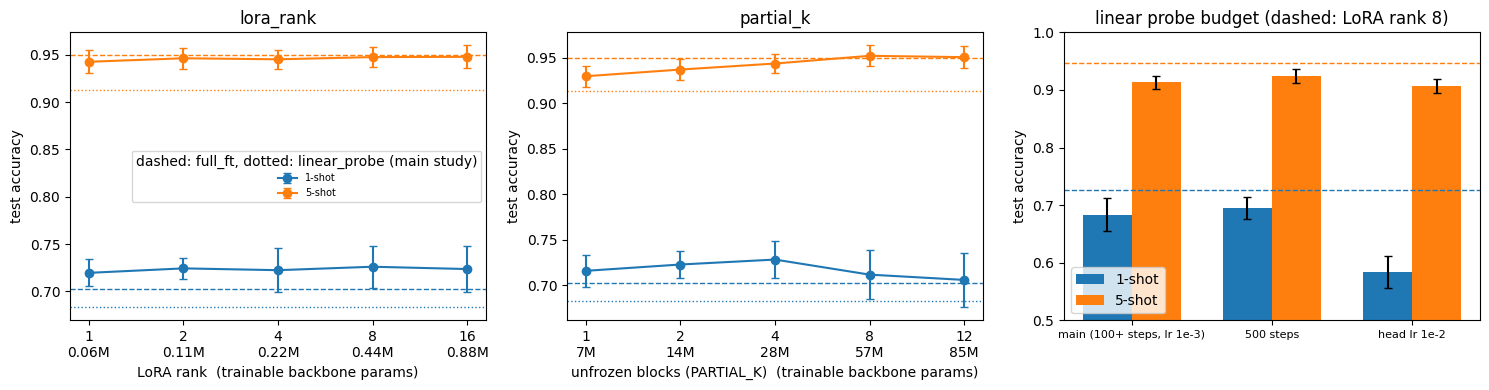

acc  acc_std  delta  delta_std
study        value   shots                                  
lora_rank    1.000   1      0.720    0.014 -0.006      0.010
                     5      0.943    0.012 -0.005      0.003
             2.000   1      0.724    0.011 -0.002      0.012
                     5      0.946    0.011 -0.001      0.002
             4.000   1      0.722    0.024 -0.004      0.008
                     5      0.945    0.010 -0.002      0.000
             8.000   1      0.726    0.022  0.000      0.000
                     5      0.947    0.011  0.000      0.000
             16.000  1      0.724    0.024 -0.002      0.008
                     5      0.948    0.012  0.000      0.002
lp_head_lr   0.001   1      0.683    0.028  0.000      0.000
                     5      0.913    0.012  0.000      0.000
             0.010   1      0.584    0.028 -0.099      0.005
                     5      0.906    0.012 -0.007      0.004
lp_min_steps 100.000 1      0.683    0.028  0.000      0.000
                     5      0.913    0.012  0.000      0.000
             500.000 1      0.695    0.019  0.012      0.010
                     5      0.924    0.012  0.011      0.002
partial_k    1.000   1      0.716    0.018 -0.012      0.003
                     5      0.929    0.012 -0.014      0.002
             2.000   1      0.723    0.015 -0.005      0.005
                     5      0.937    0.012 -0.007      0.002
             4.000   1      0.728    0.020  0.000      0.000
                     5      0.943    0.010  0.000      0.000
             8.000   1      0.712    0.027 -0.017      0.019
                     5      0.952    0.011  0.008      0.003
             12.000  1      0.706    0.030 -0.022      0.020
                     5      0.950    0.012  0.007      0.003

In [8]:
# Ablation analysis: merge the ablation runs with the matching main-study runs and plot accuracy versus the changed factor.
abl = pd.read_csv(ABLATION_CSV).drop(columns='time_s')
base = df[(df.dataset == ABL_DATASET) & (df.backbone == ABL_BACKBONE) & df.shots.isin([str(k) for k in ABL_SHOTS])]
# main-study value of each factor and the method it applies to (the reference point of every ablation)
REF = {'lora_rank': ('lora', LORA_RANK), 'partial_k': ('partial_ft', PARTIAL_K),
       'lp_min_steps': ('linear_probe', MIN_STEPS), 'lp_head_lr': ('linear_probe', HEAD_LR)}
ref_rows = [pd.DataFrame(dict(study=st, method=m, value=float(v), shots=base[base.method == m].shots.astype(int),
                              seed=base[base.method == m].seed, test_acc=base[base.method == m].test_acc))
            for st, (m, v) in REF.items()]
abl_all = pd.concat([abl] + ref_rows, ignore_index=True)
abl_all['value'] = abl_all.value.astype(float)

# paired difference w.r.t. the main-study value of the same study, seed and shot count
ref_acc = abl_all[abl_all.value == abl_all.study.map({s: float(v) for s, (m, v) in REF.items()})]
abl_all = abl_all.merge(ref_acc.rename(columns={'test_acc': 'ref_acc'})[['study', 'shots', 'seed', 'ref_acc']], on=['study', 'shots', 'seed'])
abl_all['delta'] = abl_all.test_acc - abl_all.ref_acc
tab = abl_all.groupby(['study', 'value', 'shots']).agg(acc=('test_acc', 'mean'), acc_std=('test_acc', 'std'),
                                                       delta=('delta', 'mean'), delta_std=('delta', 'std')).round(3)

main_mean = lambda m, k: base[(base.method == m) & (base.shots == str(k))].test_acc.mean()
colors = {1: 'tab:blue', 5: 'tab:orange'}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
# panels 1-2: LoRA rank and number of unfrozen blocks, with full_ft (dashed) and linear_probe (dotted) of the main study as references
for ax, study, xlabel in zip(axes[:2], ['lora_rank', 'partial_k'], ['LoRA rank', 'unfrozen blocks (PARTIAL_K)']):
    for k in ABL_SHOTS:
        g = abl_all[(abl_all.study == study) & (abl_all.shots == k)].groupby('value').test_acc.agg(['mean', 'std'])
        ax.errorbar(range(len(g)), g['mean'], g['std'], marker='o', capsize=3, color=colors[k], label=f'{k}-shot')
        ax.axhline(main_mean('full_ft', k), color=colors[k], ls='--', lw=1)
        ax.axhline(main_mean('linear_probe', k), color=colors[k], ls=':', lw=1)
    ticks = g.index.astype(int)
    # x labels also show the trainable backbone parameters (55,296 per unit of LoRA rank; about 7.08M per transformer block)
    ax.set_xticks(range(len(g)), [f'{v}\n{55296 * v / 1e6:.2f}M' if study == 'lora_rank' else f'{v}\n{7.08 * v:.0f}M' for v in ticks])
    ax.set(xlabel=xlabel + '  (trainable backbone params)', ylabel='test accuracy', title=study)
axes[0].legend(title='dashed: full_ft, dotted: linear_probe (main study)', fontsize=7)

# panel 3: linear-probe budget (more steps or a larger head lr) against the main-study probe, with LoRA rank 8 as the dashed reference
lp = abl_all[abl_all.study.isin(['lp_min_steps', 'lp_head_lr'])]
variants = [('main (100+ steps, lr 1e-3)', None), ('500 steps', ('lp_min_steps', float(MIN_STEPS) * 5)), ('head lr 1e-2', ('lp_head_lr', 1e-2))]
w = 0.35
for i, k in enumerate(ABL_SHOTS):
    vals = [base[(base.method == 'linear_probe') & (base.shots == str(k))].test_acc if v is None
            else lp[(lp.study == v[0]) & (lp.value == v[1]) & (lp.shots == k)].test_acc for _, v in variants]
    axes[2].bar(np.arange(len(vals)) + (i - 0.5) * w, [x.mean() for x in vals], w, yerr=[x.std() for x in vals], capsize=3,
                color=colors[k], label=f'{k}-shot')
    axes[2].axhline(main_mean('lora', k), color=colors[k], ls='--', lw=1)
axes[2].set_xticks(range(len(variants)), [n for n, _ in variants], fontsize=8)
axes[2].set(ylabel='test accuracy', title='linear probe budget (dashed: LoRA rank 8)', ylim=(0.5, 1))
axes[2].legend()
plt.tight_layout()
plt.show()
tab


### Ablation findings

Flowers102, CLIP ViT-B/16, 3 seeds; differences are paired by seed with the main-study value.

- **LoRA rank is not a sensitive factor.** Accuracy is flat from rank 1 to 16 (1 shot: 0.720-0.726; 5 shots: 0.943-0.948), every change is at most 0.006 and within noise. Rank 1 (about 55k trainable backbone parameters) is as good as rank 8, which supports the low intrinsic-rank hypothesis of LoRA in this regime; the fixed rank of 8 in the main study was not a limiting choice.
- **Unfreezing more blocks helps only with more data.** With 5 shots accuracy rises with the number of unfrozen blocks (k=1: 0.929, k=2: 0.937, k=4: 0.943, k=8: 0.952, k=12: 0.950; k=12 matches the main-study `full_ft`, 0.950). With 1 shot the best value is k=4 (0.728) and k=8/12 lose 0.017-0.022, which is about one standard deviation, so it is suggestive and not established.
- **The linear probe is mildly under-trained at the base budget, not badly.** 500 steps give about +0.01 at both shot counts; head lr 1e-2 is worse at 1 shot (-0.10) and about equal at 5 shots (-0.007). Even with 500 steps the probe stays below LoRA (1 shot: 0.695 vs 0.726; 5 shots: 0.924 vs 0.947).
- These runs are a sensitivity analysis on the test set. The main-study hyperparameters were not changed after seeing them.


## Replication of the CLIP-LoRA protocol

The main study differs from CLIP-LoRA (Zanella & Ben Ayed, 2024) on purpose (image tower only, zero-initialised linear head, small budget). To check that the pipeline is not the cause of the gap at 1-4 shots, this section re-implements their protocol as closely as the public description allows and compares with their Table 3 (CLIP ViT-B/16, Flowers102 and Pets):

- CLIP ViT-B/16 (OpenAI weights, `transformers`), both image and text towers adapted; the classifier is the text embedding of "a photo of a [class]." (initialised from zero-shot, logits scaled by the learned CLIP temperature).
- LoRA on the query, key and value projections of every attention block of both towers, rank 2, scaling alpha/r = 1/2, dropout 0.25 on the LoRA input, B initialised at zero.
- AdamW (lr 2e-4, weight decay 0.01), cosine schedule, batch 32, 500 x shots/class iterations, no validation set, last iterate evaluated.
- Training augmentation `RandomResizedCrop(224, scale=(0.08, 1))` + horizontal flip; test: resize 224 (bicubic) + center crop.
- Same few-shot subsets as the main study (seeds 0, 1, 2), shots 1 and 4. 16 shots (8000 steps per run) were not run.
- Known differences: official Flowers102 test split (6,149 images) instead of the CoOp split (2,463); class names from the OpenAI/CLIP-benchmark list; some implementation details (initialisation of dropout, bf16 autocast) are our choice. Zero-shot accuracy is evaluated as a sanity check of the pipeline (paper: Flowers 71.4, Pets 89.1).


In [9]:
# Replication of the CLIP-LoRA protocol (Zanella & Ben Ayed, 2024): text-initialised classifier, LoRA on both CLIP towers.
import json
from transformers import CLIPModel, CLIPTokenizer

REPLICATION_CSV = Path('results/replication.csv')
HF_CLIP = 'openai/clip-vit-base-patch16'
_names = json.load(open(DATA_ROOT / 'en_classnames.json'))  # CLIP-benchmark list, same order as the torchvision labels
CLASSNAMES = {'flowers102': _names['flowers'], 'pets': _names['pets']}
# hyperparameters of the paper: LoRA rank 2, scaling alpha/r = 1/2, dropout 0.25, AdamW lr 2e-4, 500 iterations per shot
REP = dict(rank=2, alpha=1, dropout=0.25, lr=2e-4, wd=0.01, bs=32, iters_per_shot=500)
REP_SHOTS = [1, 4]
BICUBIC = T.InterpolationMode.BICUBIC
# CLIP-style augmentation (strong random crop) and bicubic evaluation resize, as in the paper's protocol
REP_TRAIN_TF = T.Compose([T.RandomResizedCrop(224, scale=(0.08, 1.0), interpolation=BICUBIC), T.RandomHorizontalFlip(),
                          T.ToTensor(), T.Normalize(*NORM['clip_vitb16'])])
REP_TEST_TF = T.Compose([T.Resize(224, interpolation=BICUBIC), T.CenterCrop(224), T.PILToTensor()])
_REP_TEST = {}

class LoRALinearDropout(LoRALinear):
    """LoRALinear with dropout applied to the input of the low-rank branch only (the frozen path is untouched)."""
    def __init__(self, base, rank, alpha, dropout):
        super().__init__(base, rank, alpha)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.base(x) + (self.drop(x) @ self.A.T @ self.B.T) * self.scale

class ClipClassifier(nn.Module):
    """CLIP with a text-embedding classifier; LoRA on q/k/v of both towers when lora=True."""
    def __init__(self, classnames, lora):
        super().__init__()
        self.clip = CLIPModel.from_pretrained(HF_CLIP)
        tok = CLIPTokenizer.from_pretrained(HF_CLIP)
        # one prompt per class; the classifier weights are the (adapted) text embeddings of these prompts
        self.tokens = tok([f'a photo of a {c}.' for c in classnames], padding=True, return_tensors='pt')
        for p in self.clip.parameters():
            p.requires_grad = False
        if lora:
            for tower in (self.clip.vision_model, self.clip.text_model):
                for layer in tower.encoder.layers:
                    for name in ('q_proj', 'k_proj', 'v_proj'):
                        setattr(layer.self_attn, name, LoRALinearDropout(getattr(layer.self_attn, name), REP['rank'], REP['alpha'], REP['dropout']))

    def text_features(self):
        t = {k: v.to(self.clip.device) for k, v in self.tokens.items()}
        return F.normalize(self.clip.get_text_features(**t), dim=-1)

    def forward(self, x, text=None):
        # logits = learned temperature x cosine similarity between image and class-text embeddings
        text = self.text_features() if text is None else text
        return self.clip.logit_scale.exp() * F.normalize(self.clip.get_image_features(pixel_values=x), dim=-1) @ text.T

def rep_test_set(name):
    # Decode the test images once (uint8) with the replication's own evaluation transform.
    if name not in _REP_TEST:
        test = load_dataset(name, 'clip_vitb16', test_tf=REP_TEST_TF)[2]
        xs, ys = zip(*DataLoader(test, batch_size=128, num_workers=NUM_WORKERS))
        _REP_TEST[name] = (torch.cat(xs), torch.cat(ys))
    return _REP_TEST[name]

@torch.no_grad()
def rep_evaluate(model, name):
    model.eval()
    x_u8, y = rep_test_set(name)
    mean, std = (torch.tensor(v, device=DEVICE).view(1, 3, 1, 1) for v in NORM['clip_vitb16'])
    with torch.autocast(DEVICE, dtype=torch.bfloat16):
        text = model.text_features()  # computed once for the whole test set
        correct = sum((model((x_u8[i:i + 128].to(DEVICE).float() / 255 - mean) / std, text).argmax(1).cpu() == y[i:i + 128]).sum().item()
                      for i in range(0, len(y), 128))
    return correct / len(y)

def run_replication(dataset, shots, seed):
    """shots = 0: zero-shot evaluation of the same pipeline."""
    set_seed(seed)
    model = ClipClassifier(CLASSNAMES[dataset], lora=shots > 0).to(DEVICE)
    if shots > 0:
        train_ds, labels, _ = load_dataset(dataset, 'clip_vitb16', train_tf=REP_TRAIN_TF)
        idx = few_shot_indices(labels, shots, seed)  # same k-shot subsets as the main study
        loader = DataLoader(Subset(train_ds, idx), batch_size=min(REP['bs'], len(idx)), shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
        opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=REP['lr'], weight_decay=REP['wd'])
        steps = REP['iters_per_shot'] * shots
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
        model.train()
        step = 0
        while step < steps:
            for x, y in loader:
                x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
                with torch.autocast(DEVICE, dtype=torch.bfloat16):
                    loss = F.cross_entropy(model(x).float(), y)
                opt.zero_grad(set_to_none=True)
                loss.backward()
                opt.step()
                sched.step()
                step += 1
                if step == steps:
                    break
    return rep_evaluate(model, dataset)

# Resumable loop: zero-shot once per dataset (deterministic), then 1 and 4 shots for 3 seeds.
done_rep = set(zip(*[pd.read_csv(REPLICATION_CSV)[c] for c in ('dataset', 'shots', 'seed')])) if REPLICATION_CSV.exists() else set()
jobs = [(ds_, 0, 0) for ds_ in CLASSNAMES] + [(ds_, k_, s_) for ds_ in CLASSNAMES for k_ in REP_SHOTS for s_ in SEEDS]
for ds_, k_, s_ in jobs:
    if (ds_, k_, s_) in done_rep:
        continue
    t0 = time.time()
    acc_ = run_replication(ds_, k_, s_)
    row = dict(dataset=ds_, shots=k_, seed=s_, test_acc=acc_, time_s=time.time() - t0)
    pd.DataFrame([row]).to_csv(REPLICATION_CSV, mode='a', header=not REPLICATION_CSV.exists(), index=False)


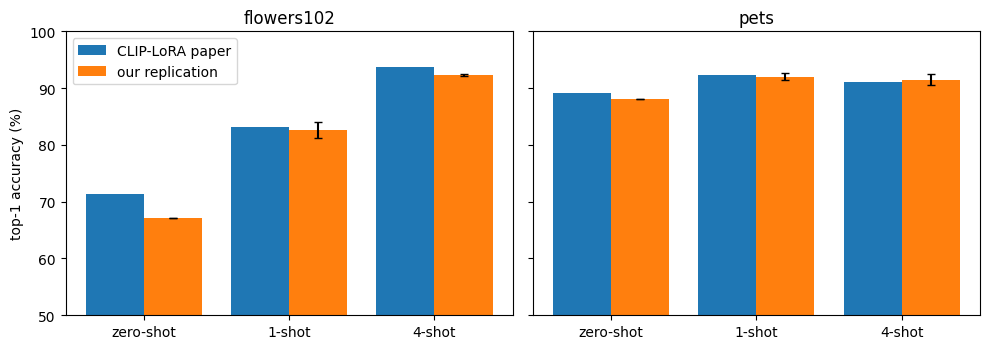

mean  std  paper  ours - paper  \
dataset    shots                                   
flowers102 0      67.2  NaN   71.4          -4.2   
           1      82.7  1.4   83.2          -0.5   
           4      92.3  0.2   93.7          -1.4   
pets       0      88.1  NaN   89.1          -1.0   
           1      92.0  0.6   92.3          -0.3   
           4      91.5  1.0   91.0           0.5   

                  main study LoRA (1 / 5 shots)  
dataset    shots                                 
flowers102 0                                NaN  
           1                               72.6  
           4                               94.7  
pets       0                                NaN  
           1                               58.1  
           4                               89.1

In [10]:
# Replication analysis: our numbers versus Table 3 of the CLIP-LoRA paper, plus the main-study LoRA for reference.
# CLIP-LoRA (Zanella & Ben Ayed 2024), Table 3, ViT-B/16, top-1 %, 3 seeds; key = (dataset, shots), 0 = zero-shot
PAPER = {('flowers102', 0): 71.4, ('flowers102', 1): 83.2, ('flowers102', 4): 93.7,
         ('pets', 0): 89.1, ('pets', 1): 92.3, ('pets', 4): 91.0}
rep = pd.read_csv(REPLICATION_CSV)
tab_rep = rep.groupby(['dataset', 'shots']).test_acc.agg(['mean', 'std']).mul(100).round(1)
tab_rep['paper'] = [PAPER[i] for i in tab_rep.index]
tab_rep['ours - paper'] = (tab_rep['mean'] - tab_rep['paper']).round(1)
# main study (image tower, zero-initialised head, 1 shot / 5 shots) for reference
main_lora = df[(df.backbone == 'clip_vitb16') & (df.method == 'lora')].groupby(['dataset', 'shots']).test_acc.mean().mul(100).round(1)
tab_rep['main study LoRA (1 / 5 shots)'] = [main_lora.get((d, {1: '1', 4: '5'}.get(k)), np.nan) for d, k in tab_rep.index]

# bar chart: paper vs our replication, one panel per dataset (the zero-shot bar has no std: single deterministic run)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, d in zip(axes, CLASSNAMES):
    g = tab_rep.loc[d]
    x = np.arange(len(g))
    ax.bar(x - 0.2, g['paper'], 0.4, label='CLIP-LoRA paper')
    ax.bar(x + 0.2, g['mean'], 0.4, yerr=g['std'].fillna(0), capsize=3, label='our replication')
    ax.set(xticks=x, xticklabels=['zero-shot' if k == 0 else f'{k}-shot' for k in g.index], title=d, ylim=(50, 100))
axes[0].set_ylabel('top-1 accuracy (%)')
axes[0].legend()
plt.tight_layout()
plt.show()
tab_rep


### Replication results

Top-1 accuracy (%), mean over 3 seeds (zero-shot: one deterministic run), CLIP-LoRA values from Table 3 of the paper.

| dataset | shots | ours | CLIP-LoRA paper | ours - paper |
|---|---|---|---|---|
| Flowers102 | 0 (zero-shot) | 67.2 | 71.4 | -4.2 |
| Flowers102 | 1 | 82.7 +- 1.4 | 83.2 | -0.5 |
| Flowers102 | 4 | 92.3 +- 0.2 | 93.7 | -1.4 |
| Pets | 0 (zero-shot) | 88.1 | 89.1 | -1.0 |
| Pets | 1 | 92.0 +- 0.6 | 92.3 | -0.3 |
| Pets | 4 | 91.5 +- 1.0 | 91.0 | +0.5 |

- **The protocol is reproduced.** The three trained cells at 1 shot (both datasets) and Pets 4-shot are within 0.5 points of the paper, inside our seed-to-seed standard deviation. Flowers 4-shot is 1.4 points lower; possible causes (not isolated) are the different test split (6,149 images vs 2,463), the class-name list, or the details of the augmentation and dropout.
- **Zero-shot is lower** (1.0 on Pets, 4.2 on Flowers) because we use the plain prompt "a photo of a [class]." while their zero-shot baseline uses hand-crafted prompts with a "type of flower/pet" context; this was not run with their prompts.
- **What this shows for the main study:** with the same CLIP backbone and LoRA, going from the main-study setting (image tower only, random zero-initialised head, about 100 steps) to the CLIP-LoRA setting (text-initialised classifier, both towers, 500 x shots steps) moves Pets 1-shot from 58.1% to 92.0% and Flowers 1-shot from 72.6% to 82.7%. The low main-study values at 1 shot are therefore a property of the protocol (no text prior), not of the pipeline. 16-shot runs (8000 steps each) were not repeated.


## Discussion

For each hypothesis: expected outcome, observed outcome, explanation. **The verdicts rest only on the EuroSAT scaling study** (end of the notebook): both backbones, 1 to 1,500 images/class, learning rate tuned per method and shot count on a validation set, 3 seeds, differences paired by seed. The earlier Flowers102/Oxford Pets experiments used fixed, untuned learning rates and at most 20-100 images/class; they are kept as exploratory evidence (last subsection) and are not used for the verdicts, because the scaling study shows that untuned learning rates distort the comparison (the supervised backbone gains up to +0.08 accuracy from tuning, CLIP much less).

- **H1 (1-5 shots: linear probe and LoRA >= full FT). Half confirmed: LoRA yes (3 of 4 cells), linear probe no.**
  - *Linear probe:* it is worse than full FT in every cell. Full FT - linear probe at 1 and 5 images/class is +0.139 and +0.108 for CLIP, +0.105 and +0.066 for the supervised backbone, with small seed std. EuroSAT (satellite images) is far from both pre-training distributions, so frozen features are a poor fit, and the gap does not close with more data (+0.048 CLIP and +0.034 supervised at 1,500 images/class).
  - *LoRA:* LoRA is at least on par with full FT in 3 of the 4 cells: supervised 1-shot full FT - LoRA = 0.000 +- 0.046 (tie), supervised 5-shot -0.031 +- 0.010 (LoRA better), CLIP 5-shot -0.001 +- 0.056 (tie). The exception is CLIP 1-shot, where full FT is better by +0.044 +- 0.009. A cause is plausible but not tested: with tuned learning rates full FT stays close to the pre-trained weights (chosen backbone lr between 3e-6 and 1e-4) and does not overfit 10 images, so its extra capacity is not penalised at this size. At CLIP 1-shot the chosen LoRA lr is the smallest of the grid (1.5e-4), so a lower value might narrow that gap.
- **H2 (more data: full FT catches up and overtakes, crossover). Not confirmed.**
  - There is no crossover with LoRA: full FT - LoRA is between -0.003 and +0.004 from 20 images/class up to 1,500 for both backbones, within the seed std. With more data the three methods that adapt the backbone converge (100 images/class: 0.949-0.958 for CLIP, 0.953-0.959 for the supervised backbone; 1,500: 0.977-0.982 for both) instead of full FT pulling ahead.
  - Partial FT (last 4 blocks) catches up with full FT at about 100 images/class: the gap goes from +0.051/+0.032/+0.034 (CLIP, 1/5/20 images) to +0.009/+0.004/+0.003 (100/500/1,500); for the supervised backbone it is +0.029 at 1 image and between -0.005 and +0.012 afterwards. The extra capacity of full FT is not needed in this range.
  - The gap to the linear probe shrinks (CLIP 0.139 to 0.048, supervised 0.105 to 0.034) but never closes.
  - Caveat: at 500-1,500 images/class every adapted method is at 0.975-0.982 on a 4,000-image test set (standard error about 0.002), so a ceiling effect may hide a crossover. The training-budget check at the end of the notebook shows that the budget is not the cause: with 3x more steps at 1,500 images/class both methods reach 0.986 and full FT - LoRA stays at 0.000 +- 0.001. The study does not exclude a crossover with a harder dataset or much more data.
- **H3 (CLIP better than supervised features in low-shot). Not confirmed on EuroSAT.**
  - Under matched conditions (same subsets, seeds, test set, budget, tuning rule, and no text tower for either backbone) CLIP - supervised at 1/5/20 images/class is -0.004/+0.007/+0.010 for the linear probe, +0.009/+0.012/-0.012 for partial FT, +0.030/+0.049/+0.010 for full FT and -0.013/+0.019/+0.002 for LoRA. Almost all of these are within one seed std (0.01-0.07). The only difference clearly above noise is full FT at 5 images/class (+0.049 +- 0.016).
  - From 100 images/class on the supervised backbone is equal or slightly better (linear probe -0.012 to -0.014, partial FT -0.004 to -0.006, full FT and LoRA within +-0.002).
  - Possible reason, not tested: EuroSAT is remote sensing, far from both ImageNet-1k and CLIP's web data, so the broader pre-training of CLIP gives little advantage; the advantage of CLIP in earlier fixed-lr experiments on Flowers102 may have been partly a tuning artefact (the supervised backbone is more sensitive to the learning rate) and partly dataset-specific. This study does not test other datasets, so it cannot say whether H3 holds elsewhere.

### Exploratory evidence from the fixed-learning-rate study (Flowers102, Oxford Pets; not used for the verdicts)

- Learning rates were fixed a priori (head 1e-3, `full_ft`/`partial_ft` 1e-5, LoRA 5e-4) and test accuracy was read at the last step. "Full" data means 20 images/class on Flowers102 and about 100/class on Pets.
- LoRA was at least on par with full FT in all 8 dataset/backbone/shot cells with 1 or 5 shots; the linear probe was worse than full FT in 7 of 8 (full FT - linear probe between +0.02 and +0.11). The linear-probe budget ablation (Flowers, CLIP) gained about +0.01 with 500 instead of 100 steps. This agrees with the EuroSAT result for H1.
- Full FT never beat LoRA or partial FT beyond noise at any shot count (full-data full FT - LoRA between -0.012 and 0.000), in line with H2. The `PARTIAL_K` ablation (Flowers, CLIP, 5 shots) increased with k (k=1: 0.929, k=4: 0.943, k=8: 0.952, k=12: 0.950).
- CLIP beat the supervised backbone on Flowers (+0.28 to +0.31 at 1 shot) but lost on Pets at 1 shot (-0.28 to -0.18); with CLIP's text-embedding classifier (replication section) CLIP reaches 92.0% on Pets at 1 shot, so the comparison there depends on the classifier initialisation. Because the learning rates were not tuned, these H3 differences are not conclusive.

### Limitations

- Verdicts come from one dataset (EuroSAT, 10 classes, 64x64 upsampled) and two ViT-B/16 backbones; the main-study datasets (Flowers102, Pets) are not covered by the tuned protocol.
- Learning rates are tuned on seed 0 only, on a validation set (1,000 images) larger than the training set below 20 images/class, so tuned results at 1-20 images/class are optimistic, equally for all methods. The selected value sits on the edge of the grid in many cells (for the supervised backbone partial FT always chose the upper edge 1e-4), so some optima may lie outside the grid; for the supervised backbone this can only make it look worse than it is, which would not strengthen a CLIP advantage.
- 3 seeds (fixed by requirement): differences below about 0.01 should be read as ties, and at 1 and 5 images/class the std (0.02-0.07) makes most comparisons suggestive.
- One value of `PARTIAL_K` (4) and one LoRA rank (8) in the scaling study; the rank and `PARTIAL_K` ablations were run only on Flowers102 with CLIP (1 and 5 shots).
- Ceiling effect at 500-1,500 images/class (all adapted methods at 0.975-0.982, 0.986 with 3x steps), a maximum of 15,000 training images, bf16 autocast, no early stopping (test accuracy measured at the last step). The budget check covers only CLIP, full FT and LoRA, at 20 and 1,500 images/class, with learning rates not re-tuned for the longer runs.


## Comparison with published results

Closest published setting: CLIP-LoRA (Zanella & Ben Ayed, 2024, arXiv:2405.18541, Tables 2-3), CLIP ViT-B/16, top-1 accuracy (%), 3 seeds. Differences in protocol: they adapt both encoders (LoRA rank 2 on q, k, v, dropout 0.25, 500 x shots/class iterations, lr 2e-4) and initialise the classifier from the text encoder ("a photo of a [class]"), so they start from zero-shot accuracy (Flowers 71.4, Pets 89.1); we use the image tower only with a randomly (zero) initialised linear head. Their Flowers test split is the CoOp one (2,463 images), ours is the official one (6,149).

| dataset | shots | CLIP-LoRA (paper) | our `lora`, CLIP | our `linear_probe`, CLIP |
|---|---|---|---|---|
| Flowers102 | 1 | 83.2 | 72.6 | 68.3 |
| Flowers102 | 4 (paper) / 5 (ours) | 93.7 | 94.7 | 91.3 |
| Flowers102 | 16 (paper) / all = 20 (ours) | 98.0 | 98.7 | 96.8 |
| Pets | 1 | 92.3 | 58.1 | 48.1 |
| Pets | 4 (paper) / 5 (ours) | 91.0 | 89.1 | 77.3 |
| Pets | 16 (paper) / all, about 100 (ours) | 92.4 | 94.9 | 93.0 |

- **In line:** Flowers with 5 or more shots (our 5-shot value lies between their 4-shot 93.7 and 8-shot 96.3; with all 20 images per class we get 98.7 vs 98.0 at 16 shots). The ordering "LoRA >= linear probe" and the fast saturation on Flowers also agree. CoOp (arXiv:2109.01134, Sec. 4.1) also reports that the CLIP linear probe is comparable to prompt tuning on Flowers102, in line with our linear probe being only about 2 points below LoRA with all data (96.8 vs 98.7).
- **Gap at 1 shot and on Pets at low shots: explained by the protocol, checked by replication.** Their numbers stay near or above zero-shot because of the text-initialised classifier; ours start from nothing (our 1-shot Flowers value is close to their zero-shot 71.4). Re-running their protocol with our code reproduces their numbers (see "Replication results" below: within 0.5 points on three of four trained cells, -1.4 on Flowers 4-shot), so the gap is not an implementation error. It also means that our Pets 1-shot deficit of CLIP vs the supervised backbone (H3) partly reflects the missing text prior and cannot be read as a statement about CLIP itself.
- **Pets with more data:** our CLIP LoRA with all data (about 100 images/class) reaches 94.9, above their 16-shot 92.4; plausible given about 6x more data. The paper itself notes that few-shot adaptation helps little on Pets and Food101.
- **Different from CoOp:** CoOp (Table 5, ImageNet, 16 shots) reports that fine-tuning the CLIP image encoder collapses (18.3%). Our full FT (lr 1e-5, warm-up, cosine) does not; the fetched text does not give their fine-tuning hyperparameters, so we cannot say why they differ.
- No published numbers were found for the supervised ViT-B/16 (ImageNet-1k) in this exact protocol, so the supervised half of the study has no external reference.


### Do the published papers support our hypotheses?

Only what the two papers report (CLIP-LoRA, arXiv:2405.18541; CoOp, arXiv:2109.01134) is used here; neither compares against a supervised ImageNet backbone.

- **H1 (linear probe and LoRA >= full FT at 1-5 shots): partly supported.** CLIP-LoRA beats prompt- and adapter-based methods at every shot count, so LoRA is a strong low-shot method. CoOp finds that the CLIP linear probe needs more than 4 shots on average to reach zero-shot accuracy and is much weaker at 1-2 shots, which agrees with our linear probe being the weakest method. CoOp's Table 5 (ImageNet, 16 shots) reports that fine-tuning the CLIP image encoder collapses (18.3% vs 58.2% zero-shot), a stronger failure of full FT than what we observe (our full FT with lr 1e-5 is competitive).
- **H2 (full FT catches up and overtakes with more data): not testable from these papers.** CLIP-LoRA accuracy grows with shots and LoRA stays on top up to 16 shots, with no full-FT baseline. CoOp notes that its class-specific variant (more parameters) is worse than the unified one below 8 shots and better with more, the same capacity-versus-data mechanism as our `PARTIAL_K` ablation, but for prompts rather than backbone layers.
- **H3 (CLIP better than supervised features at low shots): not testable from these papers.** Both only study CLIP. The only related statement is that the CLIP linear probe is a strong few-shot baseline. A direct check would need the original CLIP paper's comparison with supervised models, which we did not read.
- CLIP-LoRA also notes that few-shot adaptation helps little on OxfordPets and Food101 (they attribute it to the lack of regularisation); their Pets accuracy stays between 91 and 92.4 from 1 to 16 shots because it starts from the zero-shot classifier (89.1).


## Scaling study with tuned learning rates (EuroSAT)

**Why.** In the main study the largest training set is 20 images/class on Flowers102 (2,040 images) and about 100/class on Pets (3,680 images). H2 predicts a crossover where full fine-tuning overtakes the cheaper methods with hundreds or thousands of images per class, a regime the main study never reaches. In addition the learning rates were fixed a priori, which can favour one method (H1). This section removes both limitations on a dataset with many images per class and a domain shift from the pre-training data. Running the supervised backbone as well makes the H3 comparison like-for-like.

**Dataset.** EuroSAT RGB (27,000 Sentinel-2 images, 10 classes, 64x64, upsampled to 224). There is no official split, so a fixed stratified split (seed 1234) is used: 400 test images/class (4,000), 100 validation images/class (1,000) and a training pool of at least 1,500 images/class (Pasture has only 2,000 images in total). k-shot subsets are sampled from the pool per seed.

**Protocol.**
    "- Shots per class: 1, 5, 20, 100, 500, 1500; two backbones, the CLIP ViT-B/16 image tower and the supervised ViT-B/16 (ImageNet-1k), each with a zero-initialised linear head, and the four methods of the main study (same `PARTIAL_K` = 4 and LoRA rank 8).\n",
    "- **H3 is tested here under matched conditions:** both backbones see the same k-shot subsets (same seed), the same validation and test images, the same budget and the same learning-rate grids with the same tuning rule, and neither uses a text tower (the main-study Pets result was confounded by the zero-shot text classifier of CLIP).\n",
- For every method and shot count the learning rate is chosen from a grid of 4 values on **validation accuracy of seed 0**; the test accuracy of the chosen value is then reported over seeds 0, 1, 2 (seeds 1 and 2 are run only at the chosen value). The test set is never used for selection. Grids: linear probe head lr {3e-4, 1e-3, 3e-3, 1e-2}; `partial_ft` and `full_ft` backbone lr {3e-6, 1e-5, 3e-5, 1e-4}; LoRA lr {1.5e-4, 5e-4, 1.5e-3, 5e-3}; head lr 1e-3 for the other methods. The main-study values are in the grids.
- Budget: 10 epochs over the subset, at least 100 and at most 1,500 optimizer steps (so 500 and 1,500 images/class get 1,500 steps, about 9.6 and 3.2 epochs).
- The validation set (1,000 images) is larger than the training set at low shot counts, so tuned results at 1-20 shots are optimistic for every method in the same way.


In [11]:
# Scaling study on EuroSAT: both backbones, 1-1500 images/class, learning rate of each method tuned on a validation set.
SCALE_BACKBONES = ['clip_vitb16', 'vit_b16_sup']
SCALE_CSV = {'clip_vitb16': Path('results/scaling_eurosat.csv'), 'vit_b16_sup': Path('results/scaling_eurosat_vit_b16_sup.csv')}
SCALE_SHOTS = [1, 5, 20, 100, 500, 1500]
SCALE_MAX_STEPS = 1500  # step cap (overrides MAX_STEPS) so that the largest subsets stay affordable
SCALE_GRID = {  # method: (hyperparameter that is tuned, values); identical for both backbones
    'linear_probe': ('HEAD_LR', [3e-4, 1e-3, 3e-3, 1e-2]),
    'partial_ft': ('BODY_LR', [3e-6, 1e-5, 3e-5, 1e-4]),
    'full_ft': ('BODY_LR', [3e-6, 1e-5, 3e-5, 1e-4]),
    'lora': ('BODY_LR', [1.5e-4, 5e-4, 1.5e-3, 5e-3]),
}
N_TEST, N_VAL = 400, 100  # per class: 4,000 test and 1,000 validation images
_EURO = {}

def eurosat(backbone):
    # EuroSAT has no official split: build a fixed stratified split (seed 1234) once, shared by all runs and both backbones.
    root = DATA_ROOT / 'eurosat' / 'EuroSAT_RGB'
    if 'val' not in _EURO:
        tf_eval = T.Compose([T.Resize(224, interpolation=T.InterpolationMode.BICUBIC), T.PILToTensor()])
        ev = torchvision.datasets.ImageFolder(root, transform=tf_eval)
        y = np.asarray(ev.targets)
        rng = np.random.default_rng(1234)
        test_idx, val_idx, pool = [], [], []
        for c in np.unique(y):
            idx = rng.permutation(np.flatnonzero(y == c))
            test_idx += idx[:N_TEST].tolist()
            val_idx += idx[N_TEST:N_TEST + N_VAL].tolist()
            pool += idx[N_TEST + N_VAL:].tolist()  # the rest is the training pool the k-shot subsets are drawn from
        def tensors(ix):
            # decode once to uint8 tensors; normalisation is applied per backbone in evaluate()
            xs, ys = zip(*DataLoader(Subset(ev, ix), batch_size=128, num_workers=NUM_WORKERS))
            return torch.cat(xs), torch.cat(ys)
        _EURO.update(labels=y, pool=np.asarray(pool), val=tensors(val_idx), test=tensors(test_idx))
    if backbone not in _EURO:  # train-time augmentation/normalisation depends on the backbone
        _EURO[backbone] = torchvision.datasets.ImageFolder(root, transform=get_transform(backbone, True))
    return _EURO

def run_scaling(backbone, method, shots, lr, seed):
    """Train one configuration and return (validation accuracy, test accuracy); lr overrides the tuned hyperparameter."""
    global HEAD_LR, MAX_STEPS
    E = eurosat(backbone)
    var = SCALE_GRID[method][0]
    set_seed(seed)
    idx = E['pool'][few_shot_indices(E['labels'][E['pool']], shots, seed)]
    old_head, old_body, old_max = HEAD_LR, BODY_LR.get(method), MAX_STEPS
    try:
        # the grid tunes the head lr for the linear probe and the backbone lr for the other methods
        if var == 'HEAD_LR':
            HEAD_LR = lr
        else:
            BODY_LR[method] = lr
        MAX_STEPS = SCALE_MAX_STEPS
        model = build_model(backbone, method, 10).to(DEVICE)
        loader = DataLoader(Subset(E[backbone], idx.tolist()), batch_size=min(BATCH_SIZE, len(idx)), shuffle=True,
                            num_workers=NUM_WORKERS, pin_memory=True)
        train(model, loader, method)
        return evaluate(model, backbone, *E['val']), evaluate(model, backbone, *E['test'])
    finally:
        # restore the global hyperparameters so the main-study defaults are untouched afterwards
        HEAD_LR, MAX_STEPS = old_head, old_max
        if old_body is not None:
            BODY_LR[method] = old_body

def scale_rows(backbone):
    f = SCALE_CSV[backbone]
    return pd.read_csv(f) if f.exists() else pd.DataFrame(columns=['method', 'shots', 'lr', 'seed', 'val_acc', 'test_acc', 'time_s'])

def scale_done(backbone, method, shots, lr, seed):
    # np.isclose because the learning rates are floats stored in a CSV
    d = scale_rows(backbone)
    return bool(((d.method == method) & (d.shots == shots) & np.isclose(d.lr.astype(float), lr) & (d.seed == seed)).any())

def scale_run(backbone, method, shots, lr, seed):
    t0 = time.time()
    val_acc, test_acc = run_scaling(backbone, method, shots, lr, seed)
    row = dict(method=method, shots=shots, lr=lr, seed=seed, val_acc=val_acc, test_acc=test_acc, time_s=time.time() - t0)
    f = SCALE_CSV[backbone]
    pd.DataFrame([row]).to_csv(f, mode='a', header=not f.exists(), index=False)

# Protocol per backbone, shot count and method: try every lr of the grid on seed 0, keep the one with the best VALIDATION accuracy,
# then run seeds 1 and 2 only at that lr. The test accuracy is never used for selection. Resumable.
for bb_ in SCALE_BACKBONES:
    for shots_ in SCALE_SHOTS:
        for method_, (var_, lrs_) in SCALE_GRID.items():
            for lr_ in lrs_:  # learning-rate selection on seed 0, by validation accuracy only
                if not scale_done(bb_, method_, shots_, lr_, 0):
                    scale_run(bb_, method_, shots_, lr_, 0)
            d_ = scale_rows(bb_)
            d_ = d_[(d_.method == method_) & (d_.shots == shots_) & (d_.seed == 0)]
            best_lr_ = float(d_.loc[d_.val_acc.astype(float).idxmax(), 'lr'])
            for seed_ in SEEDS[1:]:
                if not scale_done(bb_, method_, shots_, best_lr_, seed_):
                    scale_run(bb_, method_, shots_, best_lr_, seed_)


### Reading the scaling figures

One row per backbone. **Column 1:** test accuracy against training images per class (log axis). **Column 2:** paired difference full FT - other method; a crossover would be a curve going from below 0 to above 0. **Column 3:** learning rate selected on validation; values on the edge of the grid mean the optimum may lie outside it. The tables report accuracy (mean, std over seeds), the paired differences, the selected learning rates and the tuning gain (tuned minus main-study learning rate, seed 0). The last figure and table compare the two backbones (CLIP - supervised, H3).


===== clip_vitb16: test accuracy (mean, std over seeds), difference full FT - method, selected lr, tuning gain =====


mean                                    std                      \
method full_ft linear_probe   lora partial_ft full_ft linear_probe   lora   
shots                                                                       
1        0.633        0.494  0.589      0.582   0.056        0.048  0.053   
5        0.820        0.713  0.821      0.788   0.021        0.034  0.035   
20       0.919        0.806  0.915      0.885   0.007        0.004  0.005   
100      0.958        0.888  0.958      0.949   0.006        0.007  0.001   
500      0.975        0.928  0.977      0.971   0.001        0.001  0.002   
1500     0.980        0.932  0.978      0.977   0.002        0.003  0.003   

                   
method partial_ft  
shots              
1           0.037  
5           0.043  
20          0.006  
100         0.005  
500         0.002  
1500        0.001

full_ft - linear_probe        full_ft - partial_ft         \
                        mean    std                 mean    std   
shots                                                             
1                      0.139  0.008                0.051  0.043   
5                      0.108  0.055                0.032  0.062   
20                     0.113  0.009                0.034  0.012   
100                    0.070  0.002                0.009  0.004   
500                    0.047  0.002                0.004  0.001   
1500                   0.048  0.004                0.003  0.002   

      full_ft - lora         
                mean    std  
shots                        
1              0.044  0.009  
5             -0.001  0.056  
20             0.004  0.002  
100           -0.000  0.007  
500           -0.002  0.003  
1500           0.002  0.003

method,full_ft,linear_probe,lora,partial_ft
shots,,,,
1,0.000010,0.001,0.00015,0.00010
5,0.000030,0.010,0.00050,0.00003
20,0.000003,0.003,0.00150,0.00001
100,0.000010,0.010,0.00050,0.00010
500,0.000003,0.010,0.00050,0.00010
1500,0.000003,0.010,0.00015,0.00003


test accuracy, tuned minus main-study default lr (seed 0 only):


...

mean                                    std                      \
method full_ft linear_probe   lora partial_ft full_ft linear_probe   lora   
shots                                                                       
1        0.602        0.497  0.602      0.573   0.040        0.028  0.025   
5        0.771        0.706  0.802      0.777   0.012        0.010  0.008   
20       0.910        0.796  0.913      0.897   0.003        0.010  0.010   
100      0.958        0.901  0.959      0.953   0.005        0.005  0.001   
500      0.978        0.940  0.975      0.976   0.000        0.003  0.003   
1500     0.981        0.946  0.980      0.982   0.002        0.003  0.000   

                   
method partial_ft  
shots              
1           0.044  
5           0.015  
20          0.013  
100         0.004  
500         0.002  
1500        0.000

full_ft - linear_probe        full_ft - partial_ft         \
                        mean    std                 mean    std   
shots                                                             
1                      0.105  0.018                0.029  0.008   
5                      0.066  0.021               -0.005  0.023   
20                     0.114  0.009                0.012  0.013   
100                    0.057  0.007                0.005  0.004   
500                    0.038  0.003                0.002  0.002   
1500                   0.034  0.001               -0.002  0.003   

      full_ft - lora         
                mean    std  
shots                        
1              0.000  0.046  
5             -0.031  0.010  
20            -0.003  0.007  
100           -0.001  0.004  
500            0.002  0.003  
1500           0.001  0.002

method,full_ft,linear_probe,lora,partial_ft
shots,,,,
1,0.00010,0.003,0.0050,0.0001
5,0.00003,0.003,0.0015,0.0001
20,0.00010,0.001,0.0050,0.0001
100,0.00003,0.003,0.0015,0.0001
500,0.00003,0.010,0.0015,0.0001
1500,0.00010,0.003,0.0005,0.0001


test accuracy, tuned minus main-study default lr (seed 0 only):


method,full_ft,linear_probe,lora,partial_ft
shots,,,,
1,0.062,0.002,0.043,0.047
5,0.029,-0.006,0.057,0.044
20,0.048,0.000,0.029,0.077
100,0.011,0.018,0.006,0.033
500,0.001,0.011,-0.001,0.011
1500,-0.002,0.009,0.000,0.014


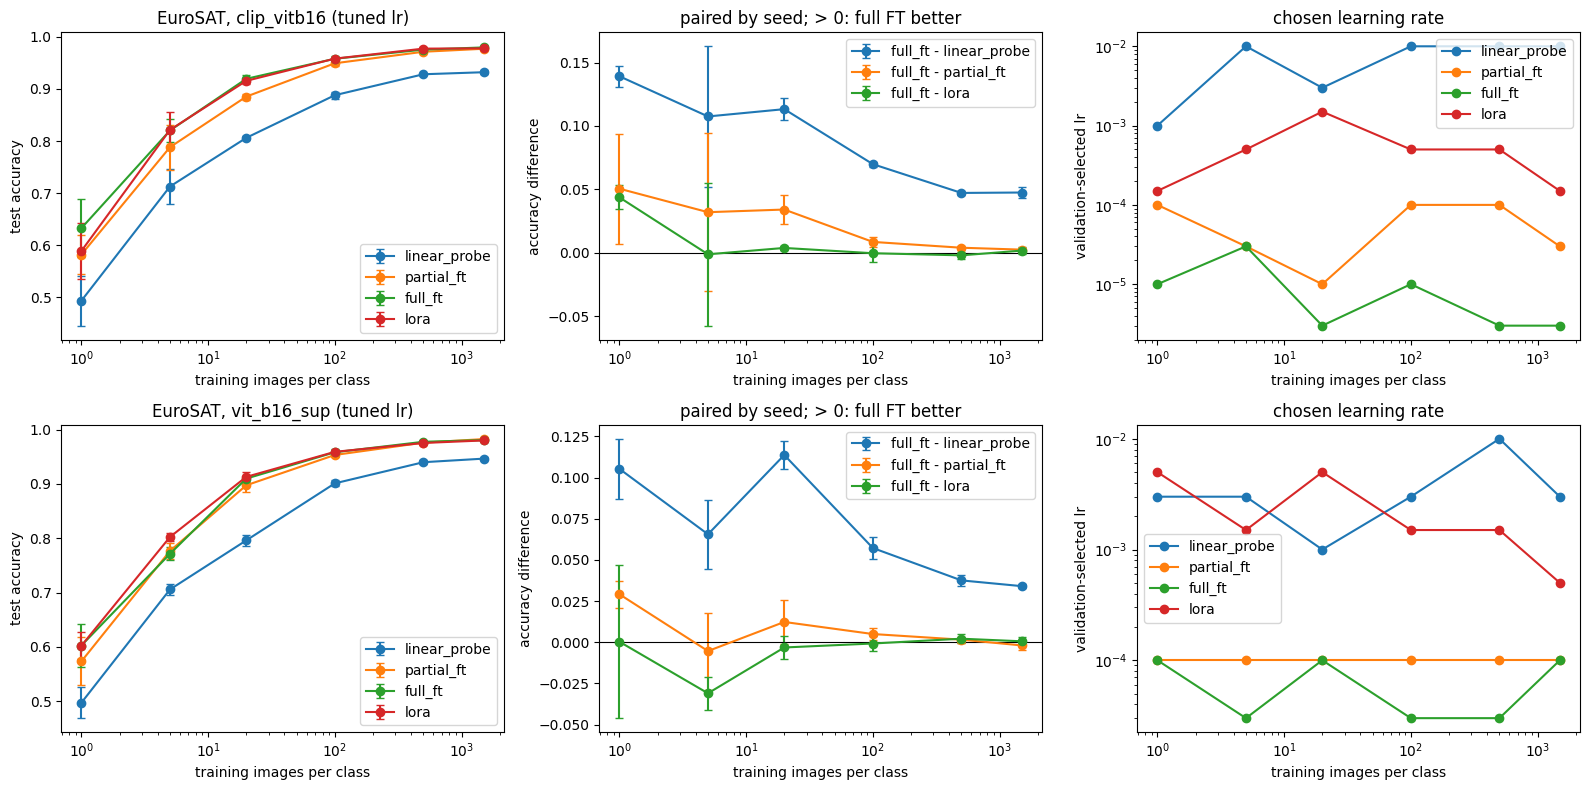

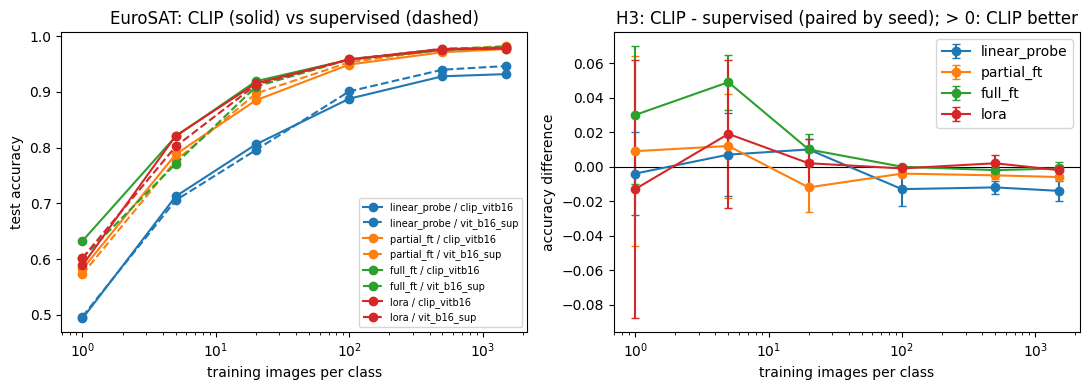

H3: CLIP - supervised, mean and std over seeds


linear_probe        partial_ft        full_ft          lora       
              mean    std       mean    std    mean    std   mean    std
shots                                                                   
1           -0.004  0.024      0.009  0.055   0.030  0.040 -0.013  0.075
5            0.007  0.024      0.012  0.030   0.049  0.016  0.019  0.043
20           0.010  0.006     -0.012  0.014   0.010  0.009  0.002  0.014
100         -0.013  0.010     -0.004  0.001  -0.000  0.001 -0.001  0.002
500         -0.012  0.004     -0.005  0.002  -0.002  0.001  0.002  0.005
1500        -0.014  0.006     -0.006  0.000  -0.001  0.004 -0.002  0.003

In [12]:
# Scaling analysis: accuracy tables and plots per backbone, then the matched CLIP-vs-supervised comparison (H3).
METH = list(SCALE_GRID)
default_lr = {'linear_probe': 1e-3, 'partial_ft': 1e-5, 'full_ft': 1e-5, 'lora': 5e-4}  # main-study values, to measure the tuning gain
FIN, PIV = {}, {}  # FIN: test rows of the selected lr per backbone; PIV: accuracy pivoted by seed (for paired differences)
fig, axes = plt.subplots(len(SCALE_BACKBONES), 3, figsize=(16, 4 * len(SCALE_BACKBONES)))
for r, bb_ in enumerate(SCALE_BACKBONES):
    if not SCALE_CSV[bb_].exists():
        continue
    sc = pd.read_csv(SCALE_CSV[bb_])
    # selected lr = best validation accuracy on seed 0 (same rule as the run cell)
    seed0 = sc[sc.seed == 0]
    best = seed0.loc[seed0.groupby(['method', 'shots']).val_acc.idxmax(), ['method', 'shots', 'lr']].rename(columns={'lr': 'best_lr'})
    fin = sc.merge(best, on=['method', 'shots'])
    fin = fin[np.isclose(fin.lr, fin.best_lr)]  # test accuracy of the validation-selected lr, seeds 0-2
    FIN[bb_] = fin

    acc_tab = fin.groupby(['shots', 'method']).test_acc.agg(['mean', 'std']).unstack('method').round(3)
    lr_tab = best.pivot(index='shots', columns='method', values='best_lr')
    piv = fin.pivot_table(index=['shots', 'seed'], columns='method', values='test_acc')
    PIV[bb_] = piv
    # paired by seed (same subset): full FT minus each other method
    diff_tab = pd.concat({f'full_ft - {m}': (piv.full_ft - piv[m]).groupby('shots').agg(['mean', 'std']) for m in METH if m != 'full_ft'}, axis=1).round(3)
    # how much tuning helps: seed-0 test accuracy at the selected lr minus at the main-study default lr
    s0 = seed0.assign(default=seed0.method.map(default_lr))
    acc_default = s0[np.isclose(s0.lr, s0.default)].set_index(['method', 'shots']).test_acc
    acc_tuned = fin[fin.seed == 0].set_index(['method', 'shots']).test_acc
    tune_gain = (acc_tuned - acc_default).unstack('method').round(3)

    # column 1: accuracy versus training images per class (log x axis)
    for m in METH:
        g = fin[fin.method == m].groupby('shots').test_acc.agg(['mean', 'std'])
        axes[r, 0].errorbar(g.index, g['mean'], g['std'], marker='o', capsize=3, label=m)
    axes[r, 0].set(xscale='log', xlabel='training images per class', ylabel='test accuracy', title=f'EuroSAT, {bb_} (tuned lr)')
    axes[r, 0].legend()
    # column 2: paired difference full FT - method; a crossover would be a curve going from below 0 to above 0
    for m in METH:
        if m != 'full_ft':
            d = (piv.full_ft - piv[m]).groupby('shots').agg(['mean', 'std'])
            axes[r, 1].errorbar(d.index, d['mean'], d['std'], marker='o', capsize=3, label=f'full_ft - {m}')
    axes[r, 1].axhline(0, color='k', lw=0.8)
    axes[r, 1].set(xscale='log', xlabel='training images per class', ylabel='accuracy difference', title='paired by seed; > 0: full FT better')
    axes[r, 1].legend()
    # column 3: selected learning rate (points on the grid edge suggest the optimum may lie outside the grid)
    for m in METH:
        axes[r, 2].plot(lr_tab.index, lr_tab[m], marker='o', label=m)
    axes[r, 2].set(xscale='log', yscale='log', xlabel='training images per class', ylabel='validation-selected lr', title='chosen learning rate')
    axes[r, 2].legend()
    print(f'===== {bb_}: test accuracy (mean, std over seeds), difference full FT - method, selected lr, tuning gain =====')
    display(acc_tab)
    display(diff_tab)
    display(lr_tab)
    print('test accuracy, tuned minus main-study default lr (seed 0 only):')
    display(tune_gain)
plt.tight_layout()
plt.show()

# H3: same seed => same k-shot subset and same test set, so CLIP - supervised is paired by seed
if len(PIV) == 2:
    h3 = pd.concat({m: (PIV['clip_vitb16'][m] - PIV['vit_b16_sup'][m]).groupby('shots').agg(['mean', 'std']) for m in METH}, axis=1).round(3)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for m in METH:
        for bb_, ls in zip(SCALE_BACKBONES, ['-', '--']):
            g = FIN[bb_][FIN[bb_].method == m].groupby('shots').test_acc.mean()
            axes[0].plot(g.index, g.values, ls, marker='o', color=f'C{METH.index(m)}', label=f'{m} / {bb_}')
        axes[1].errorbar(h3[m].index, h3[m]['mean'], h3[m]['std'], marker='o', capsize=3, label=m)
    axes[0].set(xscale='log', xlabel='training images per class', ylabel='test accuracy', title='EuroSAT: CLIP (solid) vs supervised (dashed)')
    axes[0].legend(fontsize=7)
    axes[1].axhline(0, color='k', lw=0.8)
    axes[1].set(xscale='log', xlabel='training images per class', ylabel='accuracy difference', title='H3: CLIP - supervised (paired by seed); > 0: CLIP better')
    axes[1].legend()
    plt.tight_layout()
    plt.show()
    print('H3: CLIP - supervised, mean and std over seeds')
    display(h3)


### Scaling study findings

EuroSAT, test accuracy at the validation-selected learning rate, mean +- std over 3 seeds; differences are paired by seed (same k-shot subset and test set for both backbones).

**CLIP ViT-B/16**

| images/class | full FT | LoRA | partial FT | linear probe |
|---|---|---|---|---|
| 1 | 0.633 +- 0.056 | 0.589 +- 0.053 | 0.582 +- 0.037 | 0.494 +- 0.048 |
| 5 | 0.820 +- 0.021 | 0.821 +- 0.035 | 0.788 +- 0.043 | 0.713 +- 0.034 |
| 20 | 0.919 +- 0.007 | 0.915 +- 0.005 | 0.885 +- 0.006 | 0.806 +- 0.004 |
| 100 | 0.958 +- 0.006 | 0.958 +- 0.001 | 0.949 +- 0.005 | 0.888 +- 0.007 |
| 500 | 0.975 +- 0.001 | 0.977 +- 0.002 | 0.971 +- 0.002 | 0.928 +- 0.001 |
| 1500 | 0.980 +- 0.002 | 0.978 +- 0.003 | 0.977 +- 0.001 | 0.932 +- 0.003 |

**Supervised ViT-B/16 (ImageNet-1k)**

| images/class | full FT | LoRA | partial FT | linear probe |
|---|---|---|---|---|
| 1 | 0.602 +- 0.040 | 0.602 +- 0.025 | 0.573 +- 0.044 | 0.497 +- 0.028 |
| 5 | 0.771 +- 0.012 | 0.802 +- 0.008 | 0.777 +- 0.015 | 0.706 +- 0.010 |
| 20 | 0.910 +- 0.003 | 0.913 +- 0.010 | 0.897 +- 0.013 | 0.796 +- 0.010 |
| 100 | 0.958 +- 0.005 | 0.959 +- 0.001 | 0.953 +- 0.004 | 0.901 +- 0.005 |
| 500 | 0.978 +- 0.000 | 0.975 +- 0.003 | 0.976 +- 0.002 | 0.940 +- 0.003 |
| 1500 | 0.981 +- 0.002 | 0.980 +- 0.000 | 0.982 +- 0.000 | 0.946 +- 0.003 |

**Full FT - LoRA (paired by seed, mean +- std)**

| images/class | CLIP | supervised |
|---|---|---|
| 1 | +0.044 +- 0.009 | 0.000 +- 0.046 |
| 5 | -0.001 +- 0.056 | -0.031 +- 0.010 |
| 20 | +0.004 +- 0.002 | -0.003 +- 0.007 |
| 100 | 0.000 +- 0.007 | -0.001 +- 0.004 |
| 500 | -0.002 +- 0.003 | +0.002 +- 0.003 |
| 1500 | +0.002 +- 0.003 | +0.001 +- 0.002 |

**CLIP - supervised (H3, paired by seed, mean)**

| images/class | linear probe | partial FT | full FT | LoRA |
|---|---|---|---|---|
| 1 | -0.004 | +0.009 | +0.030 | -0.013 |
| 5 | +0.007 | +0.012 | +0.049 | +0.019 |
| 20 | +0.010 | -0.012 | +0.010 | +0.002 |
| 100 | -0.013 | -0.004 | 0.000 | -0.001 |
| 500 | -0.012 | -0.005 | -0.002 | +0.002 |
| 1500 | -0.014 | -0.006 | -0.001 | -0.002 |

- **No crossover between full FT and LoRA, for either backbone.** After 20 images/class the difference stays between -0.003 and +0.004. Full FT is clearly better only for CLIP at 1 image/class (+0.044 +- 0.009); LoRA is clearly better only for the supervised backbone at 5 images/class (+0.031 +- 0.010).
- **Partial FT catches up with full FT at about 100 images/class** (CLIP gap +0.051, +0.032, +0.034 at 1, 5, 20 images, then +0.009, +0.004, +0.003; supervised gap +0.029 at 1 image, then between -0.005 and +0.012).
- **The linear probe is the weakest method at every size**, for both backbones. The gap to full FT narrows (CLIP +0.139 to +0.048, supervised +0.105 to +0.034) but never closes.
- **No consistent CLIP advantage.** Differences between the backbones are mostly within one seed std at 1-20 images/class; the only clear one is full FT at 5 images/class (+0.049 +- 0.016). From 100 images/class the supervised backbone is equal or slightly better.
- **Tuning matters, especially for the supervised backbone.** At seed 0, validation-selected learning rates change test accuracy relative to the fixed defaults of the main study by up to +0.062 (full FT), +0.057 (LoRA) and +0.077 (partial FT) for the supervised backbone at 1-20 images/class, but only by at most 0.002 (full FT), 0.024 (LoRA) and 0.030 (partial FT) for CLIP; the linear probe gains at most 0.058 for CLIP and at most 0.018 for the supervised backbone. Comparisons across backbones at fixed learning rates therefore favour CLIP.
- **Grid edges.** CLIP: linear probe at the upper edge (1e-2) for 4 of 6 shot counts, partial FT at the upper edge (1e-4) for 3, full FT at the lower edge (3e-6) for 3. Supervised: partial FT at the upper edge (1e-4) for 6 of 6, full FT at the upper edge (1e-4) for 3, LoRA at the upper edge (5e-3) for 2. Some optima may be outside the grid; a wider grid was not run.
- **Scope.** One dataset, 3 seeds, learning rate chosen on seed 0 only, and a validation set larger than the training set below 20 images/class. Standard deviations are large at 1 and 5 images/class (0.01-0.07), so differences there are suggestive. At 500-1,500 images/class all adapted methods are at 0.975-0.982, so a ceiling effect may hide differences. These results do not exclude a crossover with orders of magnitude more data or on a harder dataset.


## Training-budget check (EuroSAT, CLIP)

**Why.** The budget of the scaling study is 10 epochs, with at least 100 and at most 1,500 optimizer steps. It is epoch-limited only at 1,500 images/class (about 3.2 epochs); at 100 and 500 images/class it is already about 10 epochs, and at 20 images/class the 100-step floor gives about 14 epochs. The verdicts "no crossover" and "full FT ~ LoRA" could therefore depend on the budget, especially for full FT with a small learning rate.

**Design (fixed before running).** CLIP ViT-B/16, `full_ft` and `lora`, the validation-selected learning rate of the scaling study (not re-tuned), seeds 0, 1, 2, same subsets. Step multiplier x2 and x4 at 20 images/class (200 and 400 steps) and x3 at 1,500 images/class (4,500 steps, about 9.6 epochs, i.e. the same number of epochs as at 500 images/class). The x1 reference is the scaling-study run with the same seed and learning rate.

**Prediction.** If the budget limits the comparison, accuracy at the longer budget rises clearly (more than about 0.005) and the full FT - LoRA difference changes sign or size. If not, accuracies and the difference stay within seed noise.


In [13]:
# Training-budget check: re-run full FT and LoRA on EuroSAT/CLIP with more optimizer steps at the already selected lr.
BUDGET_CSV = Path('results/budget_check_eurosat.csv')
BUDGET_JOBS = [(20, 2), (20, 4), (1500, 3)]  # (images/class, step multiplier)
BUDGET_METHODS = ['full_ft', 'lora']

def budget_lr(method, shots):  # validation-selected lr of the scaling study (CLIP), not re-tuned
    d = scale_rows('clip_vitb16')
    d = d[(d.method == method) & (d.shots == shots) & (d.seed == 0)]
    return float(d.loc[d.val_acc.astype(float).idxmax(), 'lr'])

def run_budget(method, shots, factor, seed):
    # Scaling EPOCHS, MIN_STEPS and the step cap by the same factor multiplies the number of steps by that factor in every regime.
    global EPOCHS, MIN_STEPS, SCALE_MAX_STEPS
    old = EPOCHS, MIN_STEPS, SCALE_MAX_STEPS
    EPOCHS, MIN_STEPS, SCALE_MAX_STEPS = EPOCHS * factor, MIN_STEPS * factor, SCALE_MAX_STEPS * factor  # steps = factor x base steps
    try:
        return run_scaling('clip_vitb16', method, shots, budget_lr(method, shots), seed)
    finally:
        EPOCHS, MIN_STEPS, SCALE_MAX_STEPS = old

def budget_done():
    if not BUDGET_CSV.exists():
        return set()
    d = pd.read_csv(BUDGET_CSV)
    return set(zip(d.method, d.shots, d.factor, d.seed))

# Resumable loop over (shots, factor) x method x seed; the x1 reference is already in the scaling-study CSV.
done_b = budget_done()
for (shots_, factor_), method_, seed_ in itertools.product(BUDGET_JOBS, BUDGET_METHODS, SEEDS):
    if (method_, shots_, factor_, seed_) in done_b:
        continue
    t0 = time.time()
    lr_ = budget_lr(method_, shots_)
    val_acc, test_acc = run_budget(method_, shots_, factor_, seed_)
    row = dict(method=method_, shots=shots_, factor=factor_, seed=seed_, lr=lr_, val_acc=val_acc, test_acc=test_acc, time_s=time.time() - t0)
    pd.DataFrame([row]).to_csv(BUDGET_CSV, mode='a', header=not BUDGET_CSV.exists(), index=False)


In [14]:
# Budget-check analysis: accuracy and full FT - LoRA gap as a function of the step multiplier (needs FIN from the scaling analysis cell).
bud = pd.read_csv(BUDGET_CSV)
# x1 reference = scaling-study runs of the same seeds and learning rates
ref = FIN['clip_vitb16'][FIN['clip_vitb16'].shots.isin([s for s, _ in BUDGET_JOBS]) & FIN['clip_vitb16'].method.isin(BUDGET_METHODS)]
ref = ref.assign(factor=1)[['method', 'shots', 'factor', 'seed', 'lr', 'val_acc', 'test_acc']]
allb = pd.concat([ref, bud[ref.columns]], ignore_index=True)

acc_b = allb.groupby(['shots', 'factor', 'method']).test_acc.agg(['mean', 'std']).unstack('method').round(3)
pv = allb.pivot_table(index=['shots', 'factor', 'seed'], columns='method', values='test_acc')
gap = (pv.full_ft - pv.lora).groupby(['shots', 'factor']).agg(['mean', 'std']).round(3)
# gain of each longer run over the x1 run of the same method, shots and seed (paired)
base_ = allb[allb.factor == 1].set_index(['method', 'shots', 'seed']).test_acc
allb['gain_vs_x1'] = allb.test_acc - allb.set_index(['method', 'shots', 'seed']).index.map(base_)
gain_b = allb.groupby(['shots', 'factor', 'method']).gain_vs_x1.agg(['mean', 'std']).unstack('method').round(3)
print('test accuracy (mean, std over seeds) by step multiplier:')
display(acc_b)
print('gain over the x1 budget (paired by seed):')
display(gain_b)
print('full FT - LoRA (paired by seed):')
display(gap)


test accuracy (mean, std over seeds) by step multiplier:


mean            std       
method       full_ft   lora full_ft   lora
shots factor                              
20    1        0.919  0.915   0.007  0.005
      2        0.910  0.916   0.011  0.010
      4        0.913  0.922   0.007  0.008
1500  1        0.980  0.978   0.002  0.003
      3        0.986  0.986   0.002  0.002

gain over the x1 budget (paired by seed):


mean            std       
method       full_ft   lora full_ft   lora
shots factor                              
20    1        0.000  0.000   0.000  0.000
      2       -0.009  0.000   0.017  0.016
      4       -0.007  0.006   0.012  0.005
1500  1        0.000  0.000   0.000  0.000
      3        0.006  0.008   0.003  0.001

full FT - LoRA (paired by seed):


mean    std
shots factor              
20    1       0.004  0.002
      2      -0.006  0.009
      4      -0.009  0.011
1500  1       0.002  0.003
      3      -0.000  0.001

### Training-budget findings

EuroSAT, CLIP ViT-B/16, same learning rates as the scaling study, mean +- std over 3 seeds; gains are paired by seed with the x1 run.

| images/class | steps multiplier | full FT | LoRA | full FT - LoRA |
|---|---|---|---|---|
| 20 | x1 (100) | 0.919 +- 0.007 | 0.915 +- 0.005 | +0.004 +- 0.002 |
| 20 | x2 (200) | 0.910 +- 0.011 | 0.916 +- 0.010 | -0.006 +- 0.009 |
| 20 | x4 (400) | 0.913 +- 0.007 | 0.922 +- 0.008 | -0.009 +- 0.011 |
| 1,500 | x1 (1,500) | 0.980 +- 0.002 | 0.978 +- 0.003 | +0.002 +- 0.003 |
| 1,500 | x3 (4,500) | 0.986 +- 0.002 | 0.986 +- 0.002 | 0.000 +- 0.001 |

- **At 1,500 images/class the budget limited the absolute accuracy, not the comparison.** Three times more steps give +0.006 +- 0.003 (full FT) and +0.008 +- 0.001 (LoRA), above the 0.005 threshold of the prediction, and both methods end at 0.986. The difference between them stays at 0.000 +- 0.001, so there is still no crossover.
- **At 20 images/class more steps do not help full FT** (-0.009 +- 0.017 with x2, -0.007 +- 0.012 with x4), while LoRA gains little (0.000 +- 0.016 with x2, +0.006 +- 0.005 with x4). The full FT - LoRA difference moves from +0.004 to -0.009 +- 0.011: within the seed noise, so it is a tie, with a weak trend in favour of LoRA.
- **Conclusion.** The "full FT ~ LoRA" and "no crossover" verdicts hold at a longer budget. The 1,500 images/class accuracies of the scaling study (0.978-0.980) are about 0.006-0.008 below what a longer run reaches, which should be kept in mind when comparing them with other work. The learning rates were not re-tuned for the longer runs (full FT used 3e-6, the lower edge of the grid), and only CLIP, full FT and LoRA were checked.
